<a href="https://colab.research.google.com/github/MohamedMoussaaif/AutoEncoders/blob/main/simpleAE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader


# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [56]:
# Hyperparameters

input_size = 784
hidden_size1 = 256
hidden_size2 = 64

latente_size = 32

l_rate = 0.001
epochs_nbr = 25
batch_size = 128

In [57]:
# Transform images into tensors
transform = transforms.ToTensor()

# MNIST dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

In [58]:
class SimpleAutoEncoder(nn.Module):

  def __init__(self, input_size, hidden_size1, hidden_size2, latente_size):
    super().__init__()

    self.encoder = nn.Sequential(
        nn.Linear(input_size, hidden_size1),
        nn.ReLU(),

        nn.Linear(hidden_size1, hidden_size2),

        nn.ReLU(),

        nn.Linear(hidden_size2, latente_size),
    )

    self.decoder = nn.Sequential(
        nn.Linear(latente_size, hidden_size2),
        nn.ReLU(),

        nn.Linear(hidden_size2, hidden_size1),
        nn.ReLU(),

        nn.Linear(hidden_size1, input_size),
        nn.Sigmoid()
    )

  def forward(self, x):

        # Flatten image
        x = x.view(x.size(0), -1)

        # Compress input
        z = self.encoder(x)

        # Reconstruct input
        reconstructed = self.decoder(z)

        return reconstructed

In [60]:
model = SimpleAutoEncoder(input_size, hidden_size1, hidden_size2, latente_size).to(device)


In [61]:
# training


criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=l_rate
)

history_loss = []

for epoch in range(epochs_nbr):

  total_loss = 0

  for images, labels in train_loader:

    images = images.to(device)

    reconstructed = model(images)

    loss = criterion(reconstructed, images.view(images.size(0), -1))

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    total_loss += loss.item()

  avg_loss = total_loss / len(train_loader)
  history_loss.append(avg_loss)

  print(f"Epoch [{epoch+1}/{epochs_nbr}], Loss: {avg_loss:.6f}")

Epoch [1/25], Loss: 0.052559
Epoch [2/25], Loss: 0.025874
Epoch [3/25], Loss: 0.020941
Epoch [4/25], Loss: 0.017744
Epoch [5/25], Loss: 0.016029
Epoch [6/25], Loss: 0.014580
Epoch [7/25], Loss: 0.013387
Epoch [8/25], Loss: 0.012498
Epoch [9/25], Loss: 0.011741
Epoch [10/25], Loss: 0.011119
Epoch [11/25], Loss: 0.010589
Epoch [12/25], Loss: 0.010097
Epoch [13/25], Loss: 0.009720
Epoch [14/25], Loss: 0.009368
Epoch [15/25], Loss: 0.009067
Epoch [16/25], Loss: 0.008805
Epoch [17/25], Loss: 0.008579
Epoch [18/25], Loss: 0.008381
Epoch [19/25], Loss: 0.008177
Epoch [20/25], Loss: 0.007963
Epoch [21/25], Loss: 0.007796
Epoch [22/25], Loss: 0.007633
Epoch [23/25], Loss: 0.007503
Epoch [24/25], Loss: 0.007369
Epoch [25/25], Loss: 0.007215


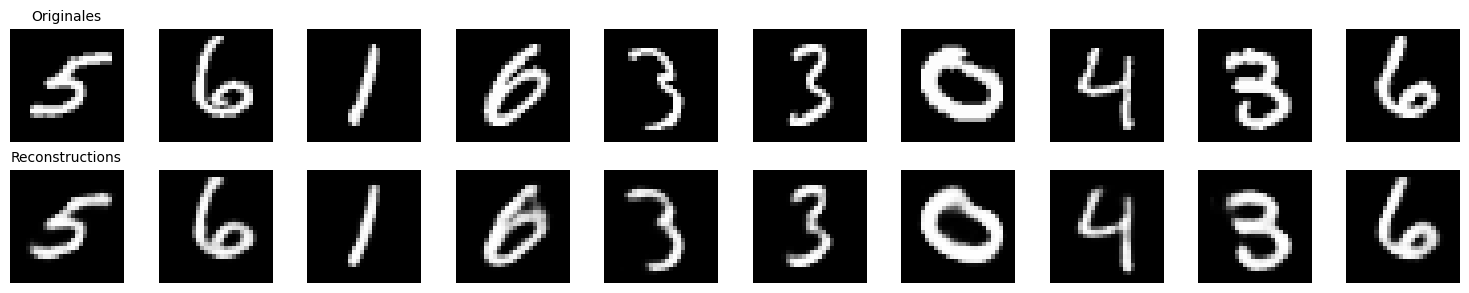

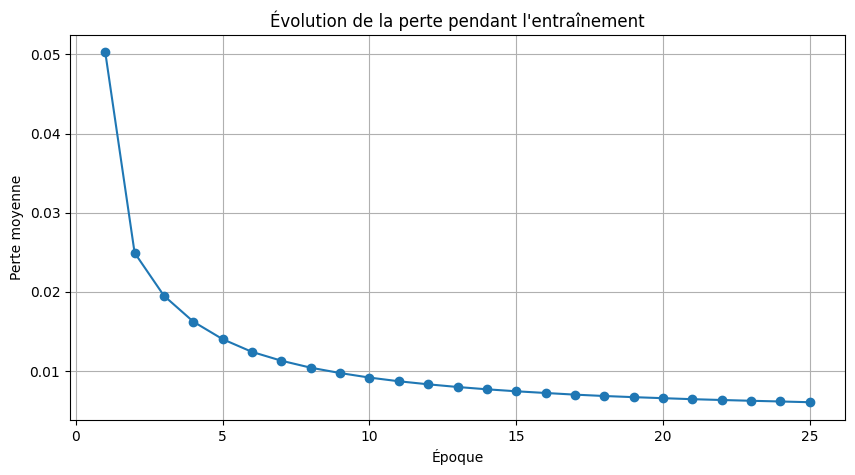


Les visualisations ont été sauvegardées!
Dimension de l'espace latent: 32 (compression de 784 à 32)
Taux de compression: 24.5x


In [55]:
# tests


with torch.no_grad():  # Désactive le calcul des gradients (économie mémoire)
    # Prend un batch d'images de test
    images_test, _ = next(iter(train_loader))
    images_test = images.to(device)
    reconstruction = model(images_test)

images_test_np = images_test.cpu().numpy()
reconstruction_np = reconstruction.cpu().numpy()

# Crée une figure avec 2 lignes: originales (haut) et reconstructions (bas)
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    # Affiche l'image originale
    axes[0, i].imshow(images_test_np[i].reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_title('Originales', fontsize=10)

    # Affiche la reconstruction
    axes[1, i].imshow(reconstruction_np[i].reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_title('Reconstructions', fontsize=10)

plt.tight_layout()
plt.savefig('autoencodeur_resultats.png', dpi=150, bbox_inches='tight')
plt.show()

# Graphique de l'évolution de la perte
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_nbr+1), history_loss, marker='o')
plt.xlabel('Époque')
plt.ylabel('Perte moyenne')
plt.title('Évolution de la perte pendant l\'entraînement')
plt.grid(True)
plt.savefig('autoencodeur_perte.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nLes visualisations ont été sauvegardées!")
print(f"Dimension de l'espace latent: {latente_size} (compression de {input_size} à {latente_size})")
print(f"Taux de compression: {input_size/latente_size:.1f}x")